# Assignment 2: Football player detection — a first step towards accessible offside tools

**Early-stage research demo | YOLO11s | amateur football**

The aim is to make useful player-detection and, eventually, assisted offside-review features more accessible to amateur clubs with ordinary video equipment. This notebook delivers the first component: detecting players and the ball in still images, evaluating the detections, and exploring a simulated human-review workflow. It does not determine offside or draw a calibrated offside line.

**Workflow:** fixed Roboflow dataset → description → fresh **or** resumed training → detection baselines → validation-selected thresholds → held-out test results → illustrative costs and staffing → exports. The Gradio dashboard is in `app.ipynb`.

### How to run this notebook

From the repo root: `uv run python main.py train`. That runs start to finish with no manual steps. It downloads dataset version **8** with your Roboflow key (read through `api_key.py`), fine-tunes YOLO11s from COCO-pretrained weights, compares it with the baselines, selects thresholds on validation, and writes `weights/best.pt` plus everything in `outputs/` that `app.ipynb` needs. Training at this size needs a GPU in practice.

- `TRAINING_MODE` defaults to `"fresh"`, which runs **6A**. To continue an interrupted run instead, set the environment variable `TRAINING_MODE=resume` and put the interrupted `last.pt` in the repo root (or point `RESUME_PATH` at it); then **6B** runs and 6A skips itself. Only one training alternative executes.
- In Colab: upload this notebook together with `api_key.py`, or add a Colab secret named `ROBOFLOW_API_KEY`. Choose a T4 GPU and **Run all**.

Resuming continues from the last completed, saved epoch, towards the original target; an unfinished epoch is repeated. A reset Colab runtime still needs dependencies and the same dataset restored. Preserve checkpoints outside temporary Colab storage if you want them to survive another runtime loss.

**Result status:** the saved outputs below come from the Colab T4 run that produced the committed `weights/best.pt`. That 40-epoch run kept hitting the free-tier runtime limit, so it was resumed from the saved `last.pt`; the final session (shown in 6B) covered epochs 31–40. Since that run, only the run mechanics have changed so that `main.py` can execute this notebook as a script: no `%pip` magics, fresh mode by default, the key read through `api_key.py`, and the Gradio cell moved to `app.ipynb`. The fresh-run epoch target now matches the 40 epochs actually used. The training, evaluation and costing code is unchanged.

## 1. Proposal, intended users and scope

### Problem and proposed value

Amateur clubs may have access to a phone recording but lack a practical way to inspect player positions consistently. The proposed direction is a low-cost video-review assistant that helps coaches and volunteer analysts find and inspect relevant frames. A later, separately validated version could offer positional overlays to support human offside review. Affordability and usefulness are hypotheses to test with clubs, rather than established outcomes.

The immediate user decision is: **which player detections can be accepted for this demo, and which candidate detections should a person inspect?** This narrower task is measurable with the available bounding-box labels. Refereeing decisions remain outside this prototype's scope.

### What is implemented, and what comes later

| Capability | Status in this notebook | Why it matters |
| --- | --- | --- |
| Player and football boxes in a still image | Implemented after training | Establishes the visual detection component |
| Per-class detection evaluation and baseline comparison | Implemented | Tests whether domain fine-tuning adds value |
| Detection-confidence sliders and image upload | Implemented in Gradio | Makes errors and review trade-offs visible |
| Human review | Simulated with perfect decisions on candidates in a confidence band | Demonstrates a possible workflow; no reviewer study or review queue is implemented |
| Team identity, player tracking and attacking direction | Future work | Needed to interpret who is attacking and defending across frames |
| Pass/contact timing, pitch calibration and positional uncertainty | Future work | Needed for meaningful spatial and temporal comparison |
| Relevant body-part localisation and rule-aware offside review | Future work | Player boxes alone cannot establish a valid offside judgement |

Under [IFAB Law 11](https://theifab.com/laws/latest/offside/), an offside-position assessment depends on eligible body parts relative to both the ball and the second-last opponent; arms and hands are excluded. Determining an offence additionally requires the relevant moment and involvement in play. The inference here is that rectangular player boxes in an uncalibrated image are insufficient for that task. A detected ball also does not identify the instant it was played.

### Users, errors and intended deployment

The first audience is a student assessor, coach or club analyst exploring recorded images. The `player` class is the positive class for the cost scenario; `football` is evaluated separately because it may support later timing research. A false negative removes a labelled player from the proposed representation. A false positive adds an unmatched candidate, including a duplicate detection. Both can degrade later analysis, but this demo cannot translate either directly into a wrong offside call.

The proposed deployment is a supervised, offline demonstration. It is not ready for match officiating, automated goal decisions or claims of certified offside accuracy. The research question is whether the detector improves over a general COCO model and offers a useful starting point for collecting amateur-football evidence.


## 2. Setup and run mode

The run that produced the committed weights used **Ultralytics 8.4.191**, Python 3.13 and PyTorch 2.11.0+cu130 on a Colab Tesla T4 (`outputs/environment.json`). The repo's uv environment locks Ultralytics 8.4.173 with CPU PyTorch, which loads these weights for evaluation and the dashboard. Missing packages are installed; existing installations are never upgraded. GPU training is strongly recommended for the 960-pixel, batch-16 configuration: on the T4, one epoch took about six minutes.

`fresh` starts a new fine-tuning run from pretrained YOLO11s weights, rather than random weights. `resume` restores an interrupted run's model and optimiser state from its `last.pt`.

In [2]:
import os, sys, subprocess, json, shutil, random, time, hashlib, warnings
from pathlib import Path
from importlib.util import find_spec
from importlib.metadata import version as package_version

# "fresh" (default) or "resume"; only one training cell runs. Override without editing:
#     TRAINING_MODE=resume uv run python main.py train
TRAINING_MODE = os.environ.get("TRAINING_MODE", "fresh").strip().lower()
if TRAINING_MODE not in {"fresh", "resume"}:
    raise ValueError('TRAINING_MODE must be "fresh" or "resume".')

ROOT = Path.cwd().resolve()
OUT = ROOT / "outputs"
WEIGHTS = ROOT / "weights"
OUT.mkdir(parents=True, exist_ok=True)
WEIGHTS.mkdir(parents=True, exist_ok=True)
RESUME_PATH = Path(os.environ.get("RESUME_PATH", ROOT / "last.pt"))  # Interrupted last.pt (Drive/full path OK).
BASE_MODEL = "yolo11s.pt"
SEED = 0
IN_COLAB = "google.colab" in sys.modules
IN_NOTEBOOK = "ipykernel" in sys.modules  # False when main.py runs this as a plain script.

# Install only missing dependencies; do not silently upgrade an existing run.
requirements = {
    "ultralytics": "ultralytics==8.4.191", "roboflow": "roboflow",
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "PIL": "pillow", "yaml": "pyyaml",
}
missing_packages = [spec for mod, spec in requirements.items() if find_spec(mod) is None]
if missing_packages:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing_packages], check=True)

import numpy as np
import pandas as pd
import matplotlib
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # Script run: save figures to outputs/, never open windows that block.
import matplotlib.pyplot as plt
import torch
import ultralytics
from PIL import Image
from ultralytics import YOLO
try:
    from IPython.display import display, Markdown
except ImportError:
    display = print
    Markdown = str

DEVICE = 0 if torch.cuda.is_available() else "cpu"
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def image_files(directory):
    return sorted(p for p in Path(directory).glob("*") if p.suffix.lower() in IMAGE_SUFFIXES)

def save_json(path, payload):
    # Strict JSON: replace non-finite numeric metrics with null, not NaN.
    def clean(value):
        if isinstance(value, dict):
            return {str(k): clean(v) for k, v in value.items()}
        if isinstance(value, (list, tuple)):
            return [clean(v) for v in value]
        if isinstance(value, Path):
            return str(value)
        if isinstance(value, np.ndarray):
            return clean(value.tolist())
        if isinstance(value, np.generic):
            return clean(value.item())
        if isinstance(value, float) and not np.isfinite(value):
            return None
        return value
    Path(path).write_text(json.dumps(clean(payload), indent=2, allow_nan=False, default=str))

environment = {"python": sys.version.split()[0], "ultralytics": ultralytics.__version__,
               "torch": torch.__version__, "cuda_available": torch.cuda.is_available(),
               "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}
save_json(OUT / "environment.json", environment)
print("Mode:", TRAINING_MODE, "| Working folder:", ROOT)
print(environment)

Mode: resume | Working folder: /content
{'python': '3.13.16', 'ultralytics': '8.4.191', 'torch': '2.11.0+cu130', 'cuda_available': True, 'device': 'Tesla T4'}


## 3. Roboflow credentials

The key is read through the repo's `api_key.py` (the `ROBOFLOW_API_KEY` environment variable, then `.env`), so both routes in SETUP.md work. A Colab secret named `ROBOFLOW_API_KEY` is the fallback when the notebook runs in Colab without `api_key.py`. The key is never printed or exported, and it is only needed if the fixed dataset version is not already present locally.

In [3]:
def get_roboflow_key():
    # Lookup order: api_key.py (env var, then .env), then a Colab secret, then a local .env.
    key = None
    try:
        from api_key import load_api_key
        key = load_api_key(required=False)
    except ImportError:
        pass  # e.g. the notebook was uploaded to Colab without api_key.py
    if not key:
        key = os.environ.get("ROBOFLOW_API_KEY")
    if not key and IN_COLAB:
        try:
            from google.colab import userdata
            key = userdata.get("ROBOFLOW_API_KEY")
        except Exception as e:
            print("Colab secret not readable:", type(e).__name__)
    if not key and Path(".env").exists():
        for line in Path(".env").read_text().splitlines():
            if line.strip().startswith("ROBOFLOW_API_KEY="):
                key = line.split("=", 1)[1].strip().strip('"').strip("'")
    if not key:
        raise RuntimeError("ROBOFLOW_API_KEY not found. Locally: copy .env.example to .env and paste your key. "
                           "In Colab: 🔑 Secrets → add ROBOFLOW_API_KEY and enable notebook access.")
    return key


print("Credential lookup is ready; the download cell requests a key only if needed.")

Credential lookup is ready; the download cell requests a key only if needed.


## 4. Fixed dataset and split integrity

This run uses Roboflow Universe's `augmented-startups/football-player-detection-kucab`, **version 8**, matching the supplied notebook log. An existing download is reused. A new version must be treated as a new experiment, rather than silently substituted during resume.

The existing training, validation and test membership is preserved. If a dataset genuinely lacks a test split, a fresh run can create one deterministically from validation; resume mode refuses to change splits. The manifest records exact image/label hashes and reports byte-identical images shared across splits. This does not detect related frames, different crops, or augmented variants from the same match: match-level independence remains unverified.

Source: [Roboflow project](https://universe.roboflow.com/augmented-startups/football-player-detection-kucab). Review its current licence and dataset terms before any broader distribution or commercial use.


In [4]:
import yaml
from collections import defaultdict

WORKSPACE = "augmented-startups"
PROJECT = "football-player-detection-kucab"
VERSION = 8
DATA_DIR = ROOT / "data" / f"{PROJECT}-v{VERSION}"

if not (DATA_DIR / "data.yaml").is_file():
    from roboflow import Roboflow
    rf = Roboflow(api_key=get_roboflow_key())
    dataset_version = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION)
    dataset_version.download("yolov8", location=str(DATA_DIR), overwrite=True)

cfg = yaml.safe_load((DATA_DIR / "data.yaml").read_text())
raw_names = cfg["names"]
CLASS_NAMES = ([raw_names[k] for k in sorted(raw_names, key=int)]
               if isinstance(raw_names, dict) else list(raw_names))
if {n.lower() for n in CLASS_NAMES} != {"player", "football"}:
    raise ValueError(f"Unexpected classes for the original run: {CLASS_NAMES}")

splits = {s: DATA_DIR / s for s in ["train", "valid", "test"]
          if image_files(DATA_DIR / s / "images")}
if not {"train", "valid"}.issubset(splits):
    raise RuntimeError("Training and validation images are required.")
if "test" not in splits:
    if TRAINING_MODE == "resume":
        raise RuntimeError("Restore the original test split before resuming; do not change split membership.")
    imgs = image_files(DATA_DIR / "valid" / "images")
    if len(imgs) < 2:
        raise RuntimeError("Not enough validation images to create a separate test split.")
    random.Random(SEED).shuffle(imgs)
    for sub in ["images", "labels"]:
        (DATA_DIR / "test" / sub).mkdir(parents=True, exist_ok=True)
    for im in imgs[:len(imgs) // 2]:
        lb = DATA_DIR / "valid" / "labels" / (im.stem + ".txt")
        shutil.move(str(im), DATA_DIR / "test" / "images" / im.name)
        if lb.exists():
            shutil.move(str(lb), DATA_DIR / "test" / "labels" / lb.name)
    splits["test"] = DATA_DIR / "test"

DATA_YAML = DATA_DIR / "data_abs.yaml"
yaml.safe_dump({"path": str(DATA_DIR), "train": str(DATA_DIR / "train/images"),
                "val": str(DATA_DIR / "valid/images"), "test": str(DATA_DIR / "test/images"),
                "nc": len(CLASS_NAMES), "names": CLASS_NAMES},
               DATA_YAML.open("w"), sort_keys=False)

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

manifest = {}
image_hash_splits = defaultdict(set)
missing_labels = {}
print("Recording image and label hashes (this can take a little time)...")
for split in ["train", "valid", "test"]:
    entries = []
    for im in image_files(DATA_DIR / split / "images"):
        lb = DATA_DIR / split / "labels" / (im.stem + ".txt")
        image_hash = sha256_file(im)
        image_hash_splits[image_hash].add(split)
        entries.append({"image": im.name, "image_sha256": image_hash,
                        "label_sha256": sha256_file(lb) if lb.exists() else None})
    if not entries:
        raise RuntimeError(f"Empty {split} split.")
    manifest[split] = entries
    missing_labels[split] = sum(e["label_sha256"] is None for e in entries)

DATA_FINGERPRINT = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()
previous_manifest_path = OUT / "dataset_manifest.json"
if previous_manifest_path.exists() and TRAINING_MODE == "resume":
    previous = json.loads(previous_manifest_path.read_text())
    if previous.get("fingerprint") != DATA_FINGERPRINT:
        raise RuntimeError("The dataset differs from the saved manifest. Restore it before resuming.")

overlap_counts = {
    f"{a}/{b}": sum(a in ss and b in ss for ss in image_hash_splits.values())
    for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]
}
DATASET_INTEGRITY_OK = not any(overlap_counts.values())
if not DATASET_INTEGRITY_OK:
    warnings.warn("Exact images cross dataset splits. Results are exploratory and potentially optimistic; "
                  "rebuild independent splits for a new experiment, not during this resumed run.")
if any(missing_labels.values()):
    warnings.warn(f"Missing label files treated as empty images; audit these annotations: {missing_labels}")

save_json(previous_manifest_path, {"fingerprint": DATA_FINGERPRINT, "splits": manifest,
                                 "cross_split_identical_images": overlap_counts,
                                 "missing_labels_treated_as_empty": missing_labels})
save_json(OUT / "dataset_source.json", {"workspace": WORKSPACE, "project": PROJECT,
          "version": VERSION, "classes": CLASS_NAMES, "fingerprint": DATA_FINGERPRINT})
print("Version:", VERSION, "| Classes:", CLASS_NAMES)
print("Images:", {s: len(manifest[s]) for s in manifest}, "| Cross-split duplicates:", overlap_counts)


Recording image and label hashes (this can take a little time)...
Version: 8 | Classes: ['football', 'player']
Images: {'train': 10308, 'valid': 972, 'test': 520} | Cross-split duplicates: {'train/valid': 0, 'train/test': 0, 'valid/test': 0}


## 5. Describe the data before training

Measure image counts, class balance, empty-labelled images and relative object sizes. A small or distant ball may occupy far fewer pixels than a player, so class-level metrics matter more than a single aggregate score. The high-resolution input is a hypothesis for retaining ball detail, with an additional memory and compute cost.


{
  "train": {
    "images": 10308,
    "empty_images": 623,
    "instances": {
      "football": 2325,
      "player": 46485
    },
    "instances_per_image": {
      "football": 0.23,
      "player": 4.51
    },
    "median_rel_area_%": {
      "football": 0.045,
      "player": 0.526
    },
    "median_rel_side_%": {
      "football": 2.13,
      "player": 7.26
    }
  },
  "valid": {
    "images": 972,
    "empty_images": 30,
    "instances": {
      "football": 275,
      "player": 5132
    },
    "instances_per_image": {
      "football": 0.28,
      "player": 5.28
    },
    "median_rel_area_%": {
      "football": 0.035,
      "player": 0.365
    },
    "median_rel_side_%": {
      "football": 1.88,
      "player": 6.04
    }
  },
  "test": {
    "images": 520,
    "empty_images": 23,
    "instances": {
      "football": 145,
      "player": 2758
    },
    "instances_per_image": {
      "football": 0.28,
      "player": 5.3
    },
    "median_rel_area_%": {
      "football": 0

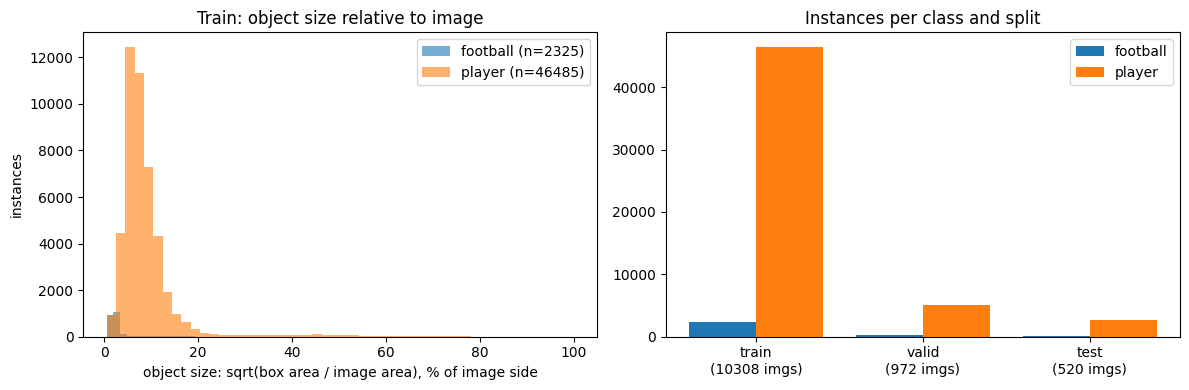

In [5]:
from PIL import Image

def read_labels(split):
    rows = []  # (image, cls, w_rel, h_rel)
    img_dir = DATA_DIR / split / "images"; lab_dir = DATA_DIR / split / "labels"
    images = sorted(p for p in img_dir.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"})
    for im in images:
        lb = lab_dir / (im.stem + ".txt")
        if lb.exists():
            for line in lb.read_text().split("\n"):
                parts = line.split()
                if len(parts) == 5:                      # bbox format
                    c, x, y, w, h = parts; rows.append((im.name, int(c), float(w), float(h)))
                elif len(parts) > 5:                     # polygon -> bbox
                    c = int(parts[0]); xs = list(map(float, parts[1::2])); ys = list(map(float, parts[2::2]))
                    rows.append((im.name, c, max(xs)-min(xs), max(ys)-min(ys)))
    return images, rows

desc = {}
for split in ["train", "valid", "test"]:
    images, rows = read_labels(split)
    counts = {n: sum(1 for r in rows if r[1] == i) for i, n in enumerate(CLASS_NAMES)}
    areas = {n: [r[2]*r[3] for r in rows if r[1] == i] for i, n in enumerate(CLASS_NAMES)}
    empty = len(images) - len({r[0] for r in rows})
    desc[split] = {"images": len(images), "empty_images": empty, "instances": counts,
                   "instances_per_image": {n: round(counts[n]/max(len(images),1), 2) for n in CLASS_NAMES},
                   "median_rel_area_%": {n: round(100*float(np.median(a)), 3) if a else None for n, a in areas.items()},
                   "median_rel_side_%": {n: round(100*float(np.median(np.sqrt(a))), 2) if a else None for n, a in areas.items()}}
    if split == "train": train_areas = areas

sizes = []
for p in image_files(DATA_DIR / "train" / "images")[:200]:
    with Image.open(p) as image:
        sizes.append(image.size)
desc["image_sizes_sample"] = {f"{w}x{h}": sizes.count((w, h)) for (w, h) in set(sizes)}
print(json.dumps(desc, indent=2))
save_json(OUT / "dataset_description.json", desc)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, n in enumerate(CLASS_NAMES):
    a = np.sqrt(np.array(train_areas[n])) * 100
    if len(a): ax[0].hist(a, bins=50, alpha=.6, label=f"{n} (n={len(a)})")
ax[0].set_xlabel("object size: sqrt(box area / image area), % of image side"); ax[0].set_ylabel("instances"); ax[0].legend()
ax[0].set_title("Train: object size relative to image")
x = np.arange(3); w = .8/len(CLASS_NAMES)
for i, n in enumerate(CLASS_NAMES):
    ax[1].bar(x + i*w, [desc[s]["instances"][n] for s in ["train","valid","test"]], w, label=n)
ax[1].set_xticks(x + w*(len(CLASS_NAMES)-1)/2, [f"{s}\n({desc[s]['images']} imgs)" for s in ["train","valid","test"]])
ax[1].set_title("Instances per class and split"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "dataset_description.png", dpi=120); plt.show(); plt.close(fig)


### Interpretation and evidence boundary

The run recorded 10,308 training images, 972 validation images and 520 test images, with `football` and `player` labels. Training contained 46,485 player instances and 2,325 football instances. The recorded median football box area was 0.045% of the image area, compared with 0.526% for players. These observations motivate separate class reporting and the original `imgsz=960` choice. The cell above computes them from the downloaded labels, and they are saved to `outputs/dataset_description.json`. Validation and test look alike (about 5.3 players and 0.28 balls per image) but are more crowded than train (4.5 players per image), with smaller objects (median player side about 6% of the image, against 7.3% in train). With only 145 test footballs, football precision/recall move by about 0.7 percentage points per object, so the football numbers are much less certain than the player numbers (2,758 test players).

An empty label file means no annotated objects, not necessarily that a person or ball is truly absent. The dataset does not provide the team identities, calibrated positions, pass timestamps or adjudicated offside incidents needed to evaluate offside accuracy. Nearby video frames or augmentation may also inflate apparent generalisation. A later study should hold out entire matches, clubs and camera settings and include ordinary amateur recordings.

## 6. Training configuration shared by both alternatives

Run this shared cell first, then use **6A or 6B**. Settings: YOLO11s, 40 epochs, image size 960, batch 16, seed 0 and patience 15; early stopping may finish sooner. These are the settings of the run that produced the committed weights. Fresh runs use a new output folder to preserve existing checkpoints. Resume restores the checkpoint's original schedule; it cannot extend it.

**Why 960 pixels and 40 epochs.** The source images are 1280×1280, and the median football is only about 2% of the image side. At 960 px a typical ball is about 20 pixels across, against about 13 at the default 640. That roughly doubles the compute per image (960² / 640² = 2.25). On a free Colab T4 one epoch took about six minutes (~645 batches), and sessions ended after roughly ten epochs, so the run was trained in several sessions and resumed from `last.pt`. Changing `EPOCHS` to 60 later did not extend the run, because resume restores the checkpoint's 40-epoch plan. More epochs would need a new run or a separate fine-tuning phase from the saved weights, and 1280-pixel training was not practical within this budget.

The exported `weights/best.pt` is the selected model used downstream. If the historical best checkpoint was lost and the resumed run never saves a replacement, the final checkpoint is exported with an explicit fallback label in metadata and the report. Saving only `last.pt` cannot reconstruct a different, lost historical `best.pt`. That happened in the submitted run: `outputs/training_settings.json` records `final_checkpoint_fallback`, so `weights/best.pt` is the epoch-40 model.

In [6]:
EPOCHS = 40  # The submitted run's target; see the note above.
IMGSZ = 960
BATCH = 16
PATIENCE = 15

def finish_training(model, started_at, mode, resume_info=None):
    global TRAIN_RUN_DIR, training_record, train_minutes
    TRAIN_RUN_DIR = Path(model.trainer.save_dir)
    train_minutes = round((time.time() - started_at) / 60, 1)
    best_path = Path(model.trainer.best)
    last_path = Path(model.trainer.last)
    best_available = best_path.is_file()
    selected = best_path if best_available else last_path
    if not selected.is_file():
        raise FileNotFoundError("Training did not produce an exportable checkpoint.")
    if not best_available:
        warnings.warn("Historical best.pt is unavailable: exporting final last.pt, not claiming the best epoch.")
    for src, dst in [(selected, WEIGHTS / "best.pt"), (last_path, WEIGHTS / "last.pt")]:
        if src.is_file() and src.resolve() != dst.resolve():
            shutil.copy2(src, dst)
    training_record = {
        **vars(model.trainer.args), "base_model": BASE_MODEL, "training_mode": mode,
        "session_minutes": train_minutes, "timing_scope": "this session only",
        "run_dir": str(TRAIN_RUN_DIR), "selected_weights_source": str(selected),
        "selected_weights_kind": "best_available" if best_available else "final_checkpoint_fallback",
        "dataset_version": VERSION, "dataset_fingerprint": DATA_FINGERPRINT,
        "environment": environment, "resume_info": resume_info,
    }
    save_json(OUT / "training_settings.json", training_record)
    print(f"Finished this session in {train_minutes} min. Exported: {WEIGHTS / 'best.pt'}")
    print("Selection:", training_record["selected_weights_kind"], "| Run folder:", TRAIN_RUN_DIR)

### 6A. Alternative A — start a fresh fine-tuning run

Run this only with `TRAINING_MODE = "fresh"`. In resume mode it prints a skip message and does no training. Starting fresh intentionally does not use your saved `last.pt`.


In [6]:
if TRAINING_MODE != "fresh":
    print("Skipped fresh training: TRAINING_MODE is resume. Run section 6B.")
else:
    train_cfg = dict(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
                     patience=PATIENCE, seed=SEED, deterministic=True, device=DEVICE,
                     project=str(ROOT / "runs"), name="football", exist_ok=False,
                     plots=True, verbose=False)
    model = YOLO(BASE_MODEL)
    t0 = time.time()
    model.train(**train_cfg)
    finish_training(model, t0, mode="fresh")


Skipped fresh training: TRAINING_MODE is resume. Run section 6B.


### 6B. Alternative B — continue from `last.pt` without starting over

Set `TRAINING_MODE` to `"resume"`. This cell first checks your configured path, then the original run folder and exported weights folder. If your checkpoint is on Drive, mount Drive and set `RESUME_PATH` in setup. If several checkpoints exist, set that path explicitly to the intended run.

The cell verifies resumable state, package version, class order and the remaining epoch target. It backs up the input checkpoint, then calls `train(resume=True)` to restore the saved training state. The checkpoint controls the schedule and original settings. An unchanged dataset version and class order are checked, but an older checkpoint without a dataset fingerprint cannot prove byte-for-byte continuity; its original data must be restored by you.

If training already finished or early-stopping finalisation stripped the optimiser state, exact resume is unavailable. This cell stops with an explanation. Further training from completed weights would be a new fine-tuning experiment and should be recorded separately. See [Ultralytics: resuming interrupted training](https://docs.ultralytics.com/modes/train/#resuming-interrupted-trainings).

In [8]:
if TRAINING_MODE != "resume":
    print("Skipped resume: TRAINING_MODE is fresh.")
else:
    candidates = [Path(RESUME_PATH).expanduser()]
    # Automatic fallbacks apply only when the default working-folder path was used.
    if candidates[0].resolve() == (ROOT / "last.pt").resolve():
        candidates += [ROOT / "runs/football/weights/last.pt", WEIGHTS / "last.pt"]
    found = [p.resolve() for p in candidates if p.is_file()]
    if not found:
        raise FileNotFoundError("Upload last.pt or set RESUME_PATH to its full path in section 2.")
    checkpoint_path = found[0]
    model = YOLO(str(checkpoint_path))
    ckpt = model.ckpt or {}
    completed_epochs = int(ckpt.get("epoch", -1)) + 1
    if completed_epochs <= 0 or ckpt.get("optimizer") is None:
        raise RuntimeError("This checkpoint has no resumable epoch/optimizer state. It may be from "
                           "a completed run. Exact resume needs last.pt saved during interrupted training.")
    saved_version = ckpt.get("version")
    if saved_version and saved_version != ultralytics.__version__:
        raise RuntimeError(f"Checkpoint uses Ultralytics {saved_version}, installed version is "
                           f"{ultralytics.__version__}. Install ultralytics=={saved_version}, "
                           "restart the runtime, and rerun setup before resuming.")
    saved_names = model.names
    saved_names = ([saved_names[k] for k in sorted(saved_names, key=int)]
                   if isinstance(saved_names, dict) else list(saved_names))
    if saved_names != CLASS_NAMES:
        raise RuntimeError(f"Checkpoint classes {saved_names} differ from dataset classes {CLASS_NAMES}.")
    train_cfg = dict(ckpt["train_args"])
    saved_data = str(train_cfg.get("data", ""))
    if "football-player-detection-kucab-v" in saved_data:
        import re
        match = re.search(r"football-player-detection-kucab-v(\d+)", saved_data)
        if match and int(match.group(1)) != VERSION:
            raise RuntimeError("Dataset version differs from checkpoint; restore the original version.")
    EPOCHS = int(train_cfg["epochs"])
    IMGSZ = train_cfg.get("imgsz", 960)
    BATCH = train_cfg.get("batch", 16)
    PATIENCE = train_cfg.get("patience", 15)
    if completed_epochs >= EPOCHS:
        raise RuntimeError(f"Already completed {completed_epochs}/{EPOCHS} epochs; nothing remains to resume.")

    prior_settings_path = OUT / "training_settings.json"
    continuity_verified = False
    if prior_settings_path.is_file():
        prior = json.loads(prior_settings_path.read_text())
        prior_fingerprint = prior.get("dataset_fingerprint")
        if prior_fingerprint and prior_fingerprint != DATA_FINGERPRINT:
            raise RuntimeError("Saved training metadata refers to a different dataset fingerprint.")
        continuity_verified = prior_fingerprint == DATA_FINGERPRINT
    if not continuity_verified:
        print("Older checkpoint has no linked dataset fingerprint; use the same original v8 data and splits.")

    backup_dir = ROOT / "checkpoint_backups"
    backup_dir.mkdir(exist_ok=True)
    backup_path = backup_dir / f"resume_input_epoch_{completed_epochs}_{time.time_ns()}.pt"
    shutil.copy2(checkpoint_path, backup_path)
    resume_info = {"checkpoint": str(checkpoint_path), "backup": str(backup_path),
                   "completed_epochs": completed_epochs, "target_epochs": EPOCHS,
                   "dataset_fingerprint_link_verified": continuity_verified}
    print(f"Resuming {checkpoint_path}: epoch {completed_epochs + 1} → {EPOCHS} total.")
    t0 = time.time()
    model.train(resume=True, data=str(DATA_YAML), device=DEVICE)
    finish_training(model, t0, mode="resume", resume_info=resume_info)


Older checkpoint has no linked dataset fingerprint; use the same original v8 data and splits.
Resuming /content/last.pt: epoch 31 → 40 total.
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/football-player-detection-kucab-v8/data_abs.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001667, lrf=0.01,

/tmp/ipykernel_5368/185474092.py:17: UserWarning: Historical best.pt is unavailable: exporting final last.pt, not claiming the best epoch.
  warnings.warn("Historical best.pt is unavailable: exporting final last.pt, not claiming the best epoch.")


## 7. Detection evaluation: fine-tuned, COCO and empty-prediction baselines

The fine-tuned model is evaluated on validation and test images; validation predictions are used later to choose thresholds. The zero-shot COCO model and a trivial model that predicts nothing are evaluated on the same test images. COCO `person` maps to `player`, and `sports ball` to `football`. This mapping is imperfect because a generic person detector does not know football roles.

All three use the same confidence-ordered, one-to-one matcher. A prediction is a true positive if it matches an unused ground-truth box of the same class at IoU ≥ 0.50. Remaining predictions are false positives; unmatched labels are false negatives. Duplicate boxes cannot match a label twice. The table reports precision/recall at the fixed comparison threshold 0.25, plus custom 101-point interpolated AP over predictions retained at confidence ≥ 0.001. These custom metrics are useful for a consistent baseline comparison, but are not claimed to reproduce every detail of the official COCO evaluator.

The NMS overlap threshold (0.60) removes duplicate predictions; it is separate from the matching IoU used for scoring. No meaningful object-detection TN count or classification accuracy is reported.


In [9]:
# One matcher for all models, so the comparison is apples to apples.
TEST_IMGS = image_files(DATA_DIR / "test/images")
VALID_IMGS = image_files(DATA_DIR / "valid/images")
if not TEST_IMGS or not VALID_IMGS:
    raise RuntimeError("Both validation and test images are required.")

def load_gt(img_path):
    with Image.open(img_path) as image:
        w, h = image.size
    lb = img_path.parent.parent / "labels" / (img_path.stem + ".txt")
    boxes = []
    if lb.exists():
        for line in lb.read_text().split("\n"):
            p = line.split()
            if len(p) == 5:
                c, x, y, bw, bh = int(p[0]), *map(float, p[1:])
            elif len(p) > 5:
                c = int(p[0]); xs = list(map(float, p[1::2])); ys = list(map(float, p[2::2]))
                x, y, bw, bh = (max(xs)+min(xs))/2, (max(ys)+min(ys))/2, max(xs)-min(xs), max(ys)-min(ys)
            else: continue
            boxes.append([c, (x-bw/2)*w, (y-bh/2)*h, (x+bw/2)*w, (y+bh/2)*h])
    return np.array(boxes, dtype=float).reshape(-1, 5)

GT = {p.name: load_gt(p) for p in TEST_IMGS}
GT_VALID = {p.name: load_gt(p) for p in VALID_IMGS}

def predict_all(yolo, class_map=None, imgsz=IMGSZ, images=None):
    # returns {img: array[N,6] = cls, conf, x1,y1,x2,y2} at conf>=0.001; class_map remaps model ids -> dataset ids
    preds = {}
    for p in (TEST_IMGS if images is None else images):
        r = yolo.predict(str(p), conf=0.001, iou=0.6, imgsz=imgsz, device=DEVICE, verbose=False, max_det=300)[0]
        b = r.boxes
        arr = np.c_[b.cls.cpu().numpy(), b.conf.cpu().numpy(), b.xyxy.cpu().numpy()] if len(b) else np.zeros((0, 6))
        if class_map is not None:
            keep = np.isin(arr[:, 0], list(class_map))
            arr = arr[keep]; arr[:, 0] = [class_map[int(c)] for c in arr[:, 0]]
        preds[p.name] = arr
    return preds

def iou(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2-x1, 0, None) * np.clip(y2-y1, 0, None)
    aa = (a[:, 2]-a[:, 0])*(a[:, 3]-a[:, 1]); ab = (b[:, 2]-b[:, 0])*(b[:, 3]-b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

def match_image(pred, gt, cls, iou_thr=0.5):
    # greedy by confidence: returns (conf of preds sorted desc, is_tp flags, matched_gt_idx, n_gt)
    P = pred[pred[:, 0] == cls]; G = gt[gt[:, 0] == cls]
    P = P[np.argsort(-P[:, 1], kind="stable")]
    tp = np.zeros(len(P), bool); mg = -np.ones(len(P), int)
    if len(P) and len(G):
        M = iou(P[:, 2:6], G[:, 1:5]); used = np.zeros(len(G), bool)
        for i in range(len(P)):
            cand = np.where((M[i] >= iou_thr) & ~used)[0]
            if len(cand):
                j = cand[np.argmax(M[i, cand])]; used[j] = True; tp[i] = True; mg[i] = j
    return P[:, 1], tp, mg, len(G)

def average_precision(preds, cls, iou_thr=0.5, ground_truth=None):
    ground_truth = GT if ground_truth is None else ground_truth
    confs, tps, n_gt = [], [], 0
    for k in ground_truth:
        c, t, _, n = match_image(preds[k], ground_truth[k], cls, iou_thr); confs.append(c); tps.append(t); n_gt += n
    if n_gt == 0: return float("nan")
    confs = np.concatenate(confs); tps = np.concatenate(tps)
    if len(confs) == 0: return 0.0
    o = np.argsort(-confs, kind="stable"); tps = tps[o]
    ctp = np.cumsum(tps); cfp = np.cumsum(~tps)
    rec = ctp / n_gt; prec = ctp / (ctp + cfp)
    prec = np.maximum.accumulate(prec[::-1])[::-1]                     # monotone envelope
    rs = np.linspace(0, 1, 101)                                         # COCO 101-point
    return float(np.mean([prec[rec >= r].max() if (rec >= r).any() else 0 for r in rs]))

def counts_at(preds, cls, thr, iou_thr=0.5, ground_truth=None):
    ground_truth = GT if ground_truth is None else ground_truth
    TP = FP = FN = 0
    for k in ground_truth:
        p = preds[k]; p = p[p[:, 1] >= thr]
        _, t, _, n = match_image(p, ground_truth[k], cls, iou_thr)
        TP += int(t.sum()); FP += int((~t).sum()); FN += n - int(t.sum())
    return TP, FP, FN

def summarize(preds, thr):
    out = {}
    for i, n in enumerate(CLASS_NAMES):
        TP, FP, FN = counts_at(preds, i, thr)
        out[n] = {"TP": TP, "FP": FP, "FN": FN,
                  "precision": round(TP/(TP+FP), 4) if TP+FP else None,
                  "recall": round(TP/(TP+FN), 4) if TP+FN else None,
                  "AP50": round(average_precision(preds, i, .5), 4),
                  "mAP50-95": round(float(np.mean([average_precision(preds, i, t) for t in np.arange(.5, .96, .05)])), 4)}
    return out

if not (WEIGHTS / "best.pt").is_file():
    raise FileNotFoundError("Run training alternative 6A or 6B first.")
finetuned = YOLO(str(WEIGHTS / "best.pt"))
print("Predicting validation images for threshold selection...")
P_FT_VALID = predict_all(finetuned, images=VALID_IMGS)
print("Predicting held-out test images...")
P_FT = predict_all(finetuned)

# Zero-shot: pretrained COCO model, mapping COCO 'person' -> player and 'sports ball' -> football
coco = YOLO(BASE_MODEL)
name2id = {n.lower(): i for i, n in enumerate(CLASS_NAMES)}
coco_map = {}
for coco_id, coco_name in coco.names.items():
    if coco_name == "person" and "player" in name2id: coco_map[coco_id] = name2id["player"]
    if coco_name == "sports ball":
        for alias in ["football", "ball"]:
            if alias in name2id: coco_map[coco_id] = name2id[alias]
print("Zero-shot class map (COCO -> dataset):", {coco.names[k]: CLASS_NAMES[v] for k, v in coco_map.items()})
if set(coco_map.values()) != set(range(len(CLASS_NAMES))):
    raise RuntimeError("COCO mapping does not cover every dataset class.")
P_ZS = predict_all(coco, coco_map)
P_NONE = {k: np.zeros((0, 6)) for k in GT}                              # trivial baseline: predict nothing

EVAL_THR = 0.25   # ultralytics default, used only for this comparison table; the cost-optimal one is chosen in §9
results = {"finetuned": summarize(P_FT, EVAL_THR), "zero_shot_coco": summarize(P_ZS, EVAL_THR), "predict_nothing": summarize(P_NONE, EVAL_THR)}
import pandas as pd
table = pd.DataFrame([{"model": m, "class": c, **v} for m, d in results.items() for c, v in d.items()])
print(f"Test split: {len(TEST_IMGS)} images, threshold {EVAL_THR}, IoU 0.5")
display(table) if IN_COLAB else print(table.to_string())
save_json(OUT / "comparison.json", {"eval_threshold": EVAL_THR, "matching_iou": 0.5,
          "nms_iou": 0.6, "prediction_conf_floor": 0.001,
          "n_test_images": len(TEST_IMGS), "n_validation_images": len(VALID_IMGS), "results": results})


Predicting validation images for threshold selection...
Predicting held-out test images...
Zero-shot class map (COCO -> dataset): {'person': 'player', 'sports ball': 'football'}
Test split: 520 images, threshold 0.25, IoU 0.5


,model,class,TP,FP,FN,precision,recall,AP50,mAP50-95
0,finetuned,football,110,32,35,0.7746,0.7586,0.8002,0.4101
1,finetuned,player,2566,149,192,0.9451,0.9304,0.9542,0.6863
2,zero_shot_coco,football,1,0,144,1.0000,0.0069,0.0173,0.0064
3,zero_shot_coco,player,132,54,2626,0.7097,0.0479,0.1841,0.0822
4,predict_nothing,football,0,0,145,NaN,0.0000,0.0000,0.0000
5,predict_nothing,player,0,0,2758,NaN,0.0000,0.0000,0.0000


## 8. Ultralytics reference metrics and test confusion matrix

For the reference AP run, predictions are retained down to confidence 0.001 so the precision–recall curve is not prematurely cut at 0.25. Ultralytics summary precision/recall are reported at its selected max-F1 operating point and may differ from the fixed-threshold comparison in section 7. A second validation call produces a confusion matrix with a 0.25 confidence floor; its matching rules can also differ from our custom matcher. The background row/column represents unmatched predictions or labels, not a count of all true-negative background regions.


Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2717.1±814.0 MB/s, size: 119.3 KB)
val: Scanning /content/data/football-player-detection-kucab-v8/test/labels... 520 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 520/520 1.9Kit/s 0.3s
val: New cache created: /content/data/football-player-detection-kucab-v8/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 1.6it/s 20.5s
                   all        520       2903       0.83      0.845      0.871       0.54
Speed: 4.0ms preprocess, 29.1ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/runs/test_ap


,precision_at_library_max_F1,recall_at_library_max_F1,AP50,mAP50-95
football,0.7269,0.7586,0.7830,0.3982
player,0.9340,0.9322,0.9582,0.6819


Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2758.7±650.1 MB/s, size: 92.3 KB)
val: Scanning /content/data/football-player-detection-kucab-v8/test/labels.cache... 520 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 520/520 136.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 1.6it/s 20.9s
                   all        520       2903      0.856      0.837      0.812      0.514
Speed: 3.1ms preprocess, 30.2ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/runs/test_eval


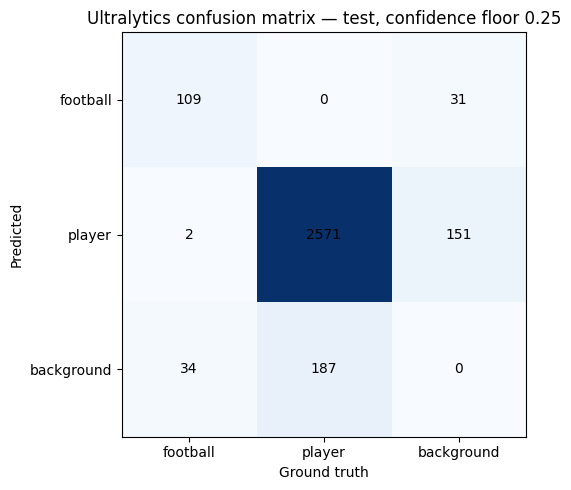

In [10]:
val = finetuned.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, conf=0.001,
                    iou=0.6, device=DEVICE, project=str(ROOT / "runs"),
                    name="test_ap", exist_ok=True, plots=True, verbose=False)
per_class = {
    CLASS_NAMES[int(c)]: {"precision_at_library_max_F1": round(float(val.box.p[i]), 4),
                         "recall_at_library_max_F1": round(float(val.box.r[i]), 4),
                         "AP50": round(float(val.box.ap50[i]), 4),
                         "mAP50-95": round(float(val.box.ap[i]), 4)}
    for i, c in enumerate(val.box.ap_class_index)
}
display(pd.DataFrame(per_class).T)
save_json(OUT / "per_class_ultralytics.json", per_class)

val_cm = finetuned.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, conf=EVAL_THR,
                      iou=0.6, device=DEVICE, project=str(ROOT / "runs"),
                      name="test_eval", exist_ok=True, plots=True, verbose=False)
cm = val_cm.confusion_matrix.matrix
cm_names = CLASS_NAMES + ["background"]
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center")
ax.set_xticks(range(len(cm_names)), cm_names)
ax.set_yticks(range(len(cm_names)), cm_names)
ax.set_xlabel("Ground truth")
ax.set_ylabel("Predicted")
ax.set_title(f"Ultralytics confusion matrix — test, confidence floor {EVAL_THR}")
fig.tight_layout()
fig.savefig(OUT / "confusion_matrix.png", dpi=120)
plt.show()
plt.close(fig)


## 9. Illustrative error costs and validation-only threshold selection

**One case is one labelled image**, used as a proxy for a candidate frame. The dataset does not establish that each image is a real offside incident. Player errors are counted per object and review effort per frame, so a frame containing several errors can incur multiple error penalties. No euro cost is assigned to true negatives because there is no defined population of negative background objects.

These are explicit **planning assumptions for demonstrating asymmetric trade-offs**, not measured losses, market prices, demonstrated savings, or a forecast of wrong refereeing decisions. They require field research before use in a business case.

| Parameter | Demo value | Rationale and limitation |
| --- | --- | --- |
| False negative | €40 per missed labelled player | A scenario penalty four times the FP penalty: missing a player can remove useful downstream positional evidence. The ratio is a design assumption, not an observed financial loss. |
| False positive | €10 per unmatched player candidate | A lower scenario penalty for an extra candidate that a reviewer may reject. No measured causal link to offside decisions is assumed. |
| True positive | €0 incremental penalty | Correct detections have no additional error penalty; compute and operating costs remain excluded. |
| Review time | 15 seconds per reviewed frame | A planning allowance for confirming/rejecting a small number of candidate boxes. Not measured; crowded frames could take longer. |
| Reviewer labour | €18/hour | Illustrative loaded labour rate, rather than a wage claim for a specific country. |
| Review overhead | €0.025/frame | Illustrative coordination allowance. Labour is 18 × 15 / 3600 = €0.075, giving **€0.10/frame total**. |
| Volume | 60 matches × 6 candidate frames = 360 frames/day | A hypothetical regional matchday. It is not an observed offside rate or a supported deployment capacity. |
| Productive time | 6 hours/reviewer/day | Planning allowance for breaks and administration. Daily FTE is an average workload, not evidence of sufficient peak-time staffing. |

The chosen threshold `T_STAR` minimises the scenario cost **on validation only**, over the stated grid. It is then applied unchanged to the held-out test set. A test cost curve is descriptive: do not use its minimum, or later slider exploration, to reselect the reported policy. Production cost would also need compute, equipment, storage, support, latency, annotation and actual reviewer-error estimates.


Validation-selected t* = 0.17; validation scenario cost €15637.86/1,000
Held-out test at fixed t*: €17346.15/1,000; TP=2584, FP=206, FN=174
Predict-nothing test proxy: €212153.85/1,000; review assumption: €0.100/frame


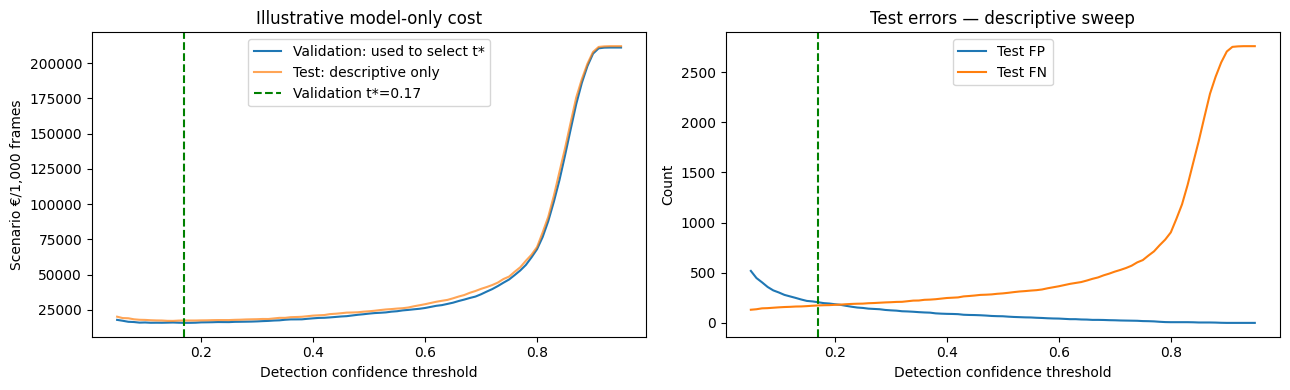

In [11]:
POS_CLASS = next(n for n in CLASS_NAMES if n.lower() == "player")
C_FN = 40.0
C_FP = 10.0
C_TP = 0.0
SECONDS_PER_REVIEW = 15
REVIEWER_EUR_PER_HOUR = 18.0
REVIEW_OVERHEAD_PER_FRAME = 0.025
C_REVIEW = REVIEWER_EUR_PER_HOUR * SECONDS_PER_REVIEW / 3600 + REVIEW_OVERHEAD_PER_FRAME
MATCHES_PER_DAY = 60
INCIDENTS_PER_MATCH = 6  # Hypothetical candidate frames, not a measured offside rate.
REVIEWER_HOURS_PER_DAY = 6
pos = CLASS_NAMES.index(POS_CLASS)
N_FRAMES = len(GT)
N_VALID = len(GT_VALID)

# Cache the confidence-ordered matches once. Thresholding cannot change an
# earlier, higher-confidence match; candidates below threshold are a suffix.
def cache_matches(preds, ground_truth, class_id):
    return [match_image(preds[k], ground_truth[k], class_id, 0.5) for k in ground_truth]

MATCH_VALID = cache_matches(P_FT_VALID, GT_VALID, pos)
MATCH_TEST = cache_matches(P_FT, GT, pos)

def counts_cached(matches, threshold):
    tp = fp = fn = 0
    for conf, flags, _, n_gt in matches:
        keep = conf >= threshold
        found = int(flags[keep].sum())
        tp += found
        fp += int((~flags[keep]).sum())
        fn += n_gt - found
    return tp, fp, fn

def cost_cached(matches, threshold, c_fn=C_FN, c_fp=C_FP):
    tp, fp, fn = counts_cached(matches, threshold)
    return (fp * c_fp + fn * c_fn + tp * C_TP) / len(matches) * 1000, tp, fp, fn

thrs = np.round(np.arange(0.05, 0.96, 0.01), 2)
sweep_valid = np.array([cost_cached(MATCH_VALID, t) for t in thrs])
best_i = int(np.argmin(sweep_valid[:, 0]))  # Deterministic tie-break: first/lower threshold.
T_STAR = float(thrs[best_i])
sweep = np.array([cost_cached(MATCH_TEST, t) for t in thrs])
TEST_SINGLE = cost_cached(MATCH_TEST, T_STAR)
cost_nothing = sum(len(g[g[:, 0] == pos]) for g in GT.values()) * C_FN / N_FRAMES * 1000
print(f"Validation-selected t* = {T_STAR:.2f}; validation scenario cost €{sweep_valid[best_i, 0]:.2f}/1,000")
print(f"Held-out test at fixed t*: €{TEST_SINGLE[0]:.2f}/1,000; TP={TEST_SINGLE[1]}, FP={TEST_SINGLE[2]}, FN={TEST_SINGLE[3]}")
print(f"Predict-nothing test proxy: €{cost_nothing:.2f}/1,000; review assumption: €{C_REVIEW:.3f}/frame")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(thrs, sweep_valid[:, 0], label="Validation: used to select t*")
axes[0].plot(thrs, sweep[:, 0], label="Test: descriptive only", alpha=0.7)
axes[0].axvline(T_STAR, ls="--", color="green", label=f"Validation t*={T_STAR:.2f}")
axes[0].set(xlabel="Detection confidence threshold", ylabel="Scenario €/1,000 frames",
            title="Illustrative model-only cost")
axes[0].legend()
axes[1].plot(thrs, sweep[:, 2], label="Test FP")
axes[1].plot(thrs, sweep[:, 3], label="Test FN")
axes[1].axvline(T_STAR, ls="--", color="green")
axes[1].set(xlabel="Detection confidence threshold", ylabel="Count", title="Test errors — descriptive sweep")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / "cost_vs_threshold.png", dpi=120)
plt.show()
plt.close(fig)


## 10. Simulated routing: accept, review or discard a detection

Detections with confidence ≥ `T_HIGH` are accepted; those below `T_LOW` are discarded; candidates in between are reviewed. A frame incurs one review charge if any player candidate is in the review band. The reviewer is assumed to confirm true candidates and reject false candidates **within that band only**. Missed players below the lower threshold remain missed. The person is not assumed to find every unproposed player.

This is a labelled-data simulation, not an implemented human service. Perfect candidate review is an optimistic assumption, while leaving all unproposed players missed limits what review can recover. The comparison with checking every frame assumes a perfect full-frame reviewer and is an idealised reference.

The band is selected on validation and evaluated unchanged on test. `PASS`/`FAIL` in the dashboard mean detection accepted/no detection accepted, not onside/offside, frame correctness or an official decision. A frame with no accepted players still needs a separate practical fallback; it cannot be assumed safe.


In [12]:
def routed_cached(matches, t_low, t_high, c_fn=C_FN, c_fp=C_FP, c_review=C_REVIEW):
    if not 0 <= t_low <= t_high <= 1:
        raise ValueError("Require 0 <= lower threshold <= upper threshold <= 1.")
    tp = fp = fn = reviewed = 0
    for conf, flags, _, n_gt in matches:
        keep = conf >= t_low
        band = keep & (conf < t_high)
        reviewed += int(band.any())
        found = int(flags[keep].sum())
        tp += found
        fp += int((~flags & keep & ~band).sum())
        fn += n_gt - found
    cost = (fp * c_fp + fn * c_fn + tp * C_TP + reviewed * c_review) / len(matches) * 1000
    return {"cost_per_1000": cost, "TP": tp, "FP": fp, "FN": fn,
            "reviewed_frames": reviewed, "review_share": reviewed / len(matches)}

grid = np.round(np.arange(0.05, 0.96, 0.05), 2)

def choose_review_policy(matches, c_fn=C_FN, c_fp=C_FP, c_review=C_REVIEW):
    candidates = [(float(lo), float(hi), routed_cached(matches, lo, hi, c_fn, c_fp, c_review))
                  for lo in grid for hi in grid if hi >= lo]
    # Break equal-cost ties by lower review burden, then the threshold pair.
    return min(candidates, key=lambda x: (x[2]["cost_per_1000"], x[2]["review_share"], x[0], x[1]))

T_LOW, T_HIGH, R_VALID = choose_review_policy(MATCH_VALID)
R = routed_cached(MATCH_TEST, T_LOW, T_HIGH)
frames_per_day = MATCHES_PER_DAY * INCIDENTS_PER_MATCH

def staffing(review_share):
    reviews = frames_per_day * review_share
    hours = reviews * SECONDS_PER_REVIEW / 3600
    return reviews, hours, hours / REVIEWER_HOURS_PER_DAY

options = {
    "Predict-nothing proxy": {"cost_per_1000": cost_nothing, "review_share": 0.0},
    "Perfect person checks every frame (idealised)": {"cost_per_1000": 1000 * C_REVIEW, "review_share": 1.0},
    f"Model alone at validation t*={T_STAR:.2f}": {"cost_per_1000": TEST_SINGLE[0], "review_share": 0.0},
    f"Model + validation review band [{T_LOW:.2f}, {T_HIGH:.2f})": R,
}
rows = []
for name, outcome in options.items():
    reviews, hours, fte = staffing(outcome["review_share"])
    rows.append({"strategy": name, "scenario_eur_per_1000": round(outcome["cost_per_1000"], 3),
                 "review_share": outcome["review_share"],
                 "scenario_eur_per_day": round(outcome["cost_per_1000"] * frames_per_day / 1000, 3),
                 "reviews_per_day": round(reviews, 2), "review_hours_per_day": round(hours, 3),
                 "reviewer_FTE": round(fte, 3), "people_if_work_is_pooled": int(np.ceil(fte))})
routing = pd.DataFrame(rows)
print(f"Validation-selected band [{T_LOW:.2f}, {T_HIGH:.2f}); fixed-policy test outcome:", R)
print(f"Hypothetical daily volume: {frames_per_day} candidate frames")
display(routing)


Validation-selected band [0.05, 0.90); fixed-policy test outcome: {'cost_per_1000': 10173.846153846152, 'TP': 2627, 'FP': 0, 'FN': 131, 'reviewed_frames': 504, 'review_share': 0.9692307692307692}
Hypothetical daily volume: 360 candidate frames


,strategy,scenario_eur_per_1000,review_share,scenario_eur_per_day,reviews_per_day,review_hours_per_day,reviewer_FTE,people_if_work_is_pooled
0,Predict-nothing proxy,212153.846,0.000000,76375.385,0.00,0.000,0.000,0
1,Perfect person checks every frame (idealised),100.000,1.000000,36.000,360.00,1.500,0.250,1
2,Model alone at validation t*=0.17,17346.154,0.000000,6244.615,0.00,0.000,0.000,0
3,"Model + validation review band [0.05, 0.90)",10173.846,0.969231,3662.585,348.92,1.454,0.242,1


## 11. Sensitivity to assumptions

The penalty ratio and review price were not measured, so the apparent optimum should be tested against alternative assumptions. The following table changes the FN penalty and review price, reselecting policies **only on validation**. It does not search for a better test-set result or overwrite the primary policy. If small assumption changes produce large changes in review burden or thresholds, the product decision needs stronger field evidence.


In [13]:
sensitivity_rows = []
for fn_multiplier in [0.25, 0.5, 1.0, 2.0]:
    for review_multiplier in [0.5, 1.0, 2.0]:
        c_fn = C_FN * fn_multiplier
        c_review = C_REVIEW * review_multiplier
        trial_costs = [cost_cached(MATCH_VALID, t, c_fn=c_fn)[0] for t in thrs]
        trial_t = float(thrs[int(np.argmin(trial_costs))])
        lo, hi, outcome = choose_review_policy(MATCH_VALID, c_fn=c_fn, c_review=c_review)
        sensitivity_rows.append({"FN_penalty_eur": c_fn, "FP_penalty_eur": C_FP,
                                 "review_eur_per_frame": round(c_review, 4),
                                 "validation_model_t": trial_t, "validation_low": lo,
                                 "validation_high": hi, "validation_review_share": outcome["review_share"],
                                 "validation_scenario_eur_per_1000": outcome["cost_per_1000"]})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(4))
save_json(OUT / "sensitivity.json", sensitivity.to_dict(orient="records"))


,FN_penalty_eur,FP_penalty_eur,review_eur_per_frame,validation_model_t,validation_low,validation_high,validation_review_share,validation_scenario_eur_per_1000
0,10.0,10.0,0.05,0.32,0.05,0.9,0.9558,2311.1626
1,10.0,10.0,0.10,0.32,0.05,0.9,0.9558,2358.9506
2,10.0,10.0,0.20,0.32,0.05,0.9,0.9558,2454.5267
3,20.0,10.0,0.05,0.25,0.05,0.9,0.9558,4574.5370
4,20.0,10.0,0.10,0.25,0.05,0.9,0.9558,4622.3251
5,20.0,10.0,0.20,0.25,0.05,0.9,0.9558,4717.9012
6,40.0,10.0,0.05,0.17,0.05,0.9,0.9558,9101.2860
7,40.0,10.0,0.10,0.17,0.05,0.9,0.9558,9149.0741
8,40.0,10.0,0.20,0.17,0.05,0.9,0.9558,9244.6502
9,80.0,10.0,0.05,0.07,0.05,0.9,0.9558,18154.7840


## 12. Visual inspection of held-out frames

Inspect detections for crowding, occlusion, small balls, touchline people and duplicates. Four randomly chosen test images are an illustration, not a representative error audit. Boxes show model detections at the validation-selected confidence threshold; they are not calibrated player positions or offside lines.


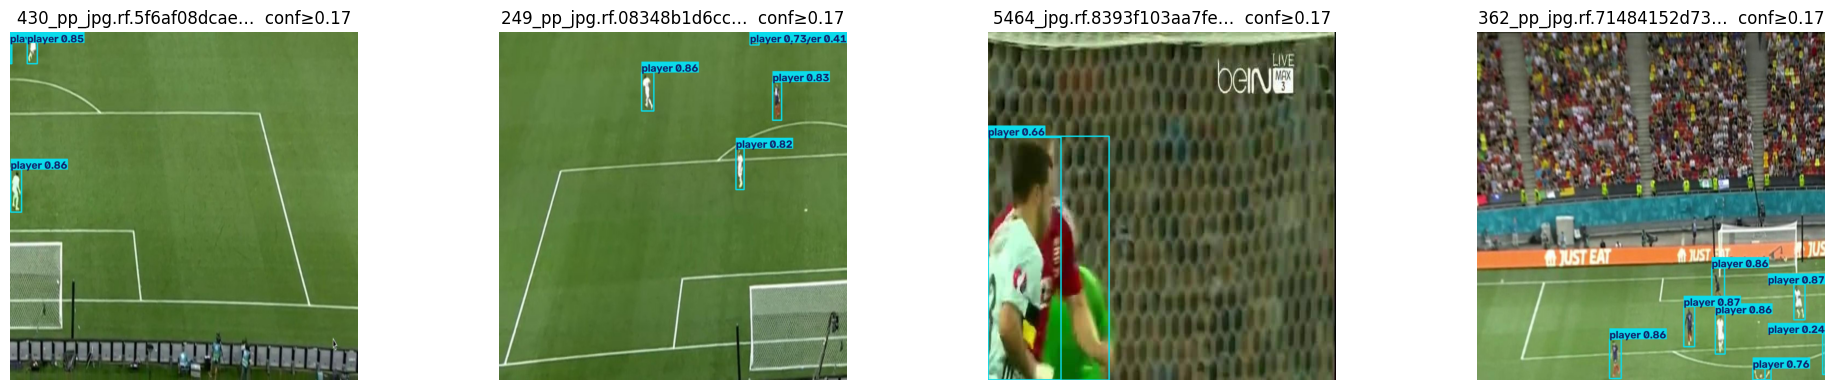

In [14]:
sample = random.Random(1).sample(TEST_IMGS, min(4, len(TEST_IMGS)))
fig, axes = plt.subplots(1, len(sample), figsize=(5*len(sample), 4))
for ax, p in zip(np.atleast_1d(axes), sample):
    r = finetuned.predict(str(p), conf=T_STAR, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    ax.imshow(r.plot()[:, :, ::-1]); ax.set_title(f"{p.name[:25]}…  conf≥{T_STAR:.2f}"); ax.axis("off")
plt.tight_layout(); plt.savefig(OUT/"sample_predictions.png", dpi=110); plt.show(); plt.close(fig)


## 13. Decision, limitations and development plan

### Decision at this stage

Proceed with a **supervised research demonstration and evidence collection**. Do not deploy this version to make or recommend official offside calls. Its contribution is a reproducible player/ball detection experiment and an interface for exploring errors and review trade-offs. Whether fine-tuning improves detection, and by how much, must be established by the generated results rather than assumed in advance.

Success for this stage means a run can be resumed, models are compared fairly on the same labelled population, validation chooses the policy, and a person can inspect detections and limitations. Strong detection scores would support further development; they would not establish offside accuracy or performance on amateur phone footage. No deployment service-level target is justified yet.

### What still limits the evidence

- **Domain and independence:** this is a public image dataset. Performance on unseen amateur grounds, cameras, lighting, weather and player kits has not been established. Exact duplicate checks do not prove match-level separation.
- **Labels and image coverage:** missing or incomplete annotations affect measured FP/FN rates. Players outside the frame cannot be detected. Ball visibility and crowded scenes need dedicated audits.
- **Task coverage:** team identification, pitch calibration, pass timing, relevant body parts, temporal tracking and rule interpretation are absent. Detection AP is not offside accuracy; confidence is not a calibrated probability that a decision is correct.
- **Human and economic assumptions:** reviewer speed and correctness are simulated; euro penalties are illustrative. Detection-error counts cannot establish actual appeal costs, player harm, monetary savings or staff requirements.
- **Training budget:** 40 epochs at 960 px on a free Colab T4, split across sessions. Only epochs 31–40 kept their history, and the historical best checkpoint was lost, so the committed weights are the final epoch rather than a validated best epoch. Training losses were still falling at epoch 40, while validation mAP was roughly flat over epochs 31–40.
- **Runtime and deployment:** latency on affordable devices, upload/storage costs, availability, security and reviewer ergonomics are not benchmarked. The Gradio interface is a demo, not an operational review service.

### Proposed next steps

1. Collect permissioned amateur footage from multiple clubs and camera positions. Keep entire matches separate across training, validation and a locked external test set; audit annotation quality and representative failure modes.
2. Benchmark detection recall/precision, localisation quality, ball visibility and latency on realistic hardware. Agree performance targets with coaches, analysts and officials before using those targets as acceptance criteria.
3. Add team identity and tracking, pitch/camera calibration with uncertainty, and pass-contact timing. Evaluate each component separately before combining them; a simple image-space line is not a validated offside boundary.
4. Develop relevant-body-part localisation and a rule-aware positional comparison, then conduct a blinded expert-reviewed study of complete incidents, including ambiguous or unjudgeable cases.
5. Measure review time, workload, reviewer errors and usability. Replace scenario costs with observed inputs, include operating costs, and test whether human assistance improves over existing practice.
6. Consider a limited human-led pilot only after those gates are met. Keep officials in control and provide an explicit cannot-judge outcome when coverage or uncertainty prevents a reliable assessment.

### AI assistance and sources

The uploaded notebook contains code originally generated with Claude. This revision used ChatGPT/Codex to add the resume alternative, refine the narrative and repair evaluation/reporting code. Claude was used again to consolidate the notebooks into the assignment repository (making them run through `main.py`) and to help assemble REPORT.md from this notebook's content and the run outputs. These are AI-assisted drafts; the submitting author must review them, own the final framing and assumptions, and report the results of the actual run. No experimental metric has been invented to complete the narrative.

- [Dataset project on Roboflow Universe](https://universe.roboflow.com/augmented-startups/football-player-detection-kucab) — version fixed to 8 in code.
- [Ultralytics training and resume documentation](https://docs.ultralytics.com/modes/train/) — checkpoint-based training continuation.
- [Ultralytics validation documentation](https://docs.ultralytics.com/modes/val/) — confidence floors and reference metrics.
- [IFAB Law 11](https://theifab.com/laws/latest/offside/) — explains why detection alone does not establish an offside offence.

## 14. Export metrics, selected weights and a result-driven report

This cell writes predictions and metrics for reproducibility, copies available plots from the actual run folders, and generates `outputs/REPORT.md` using the computed values. It does not claim that historical training curves are complete if only `last.pt` survived. The ZIP includes exported weights, outputs and the report; it does not contain dataset images or credentials. Back up the original run folder separately if you also need its full history.


In [15]:
export = {"class_names": CLASS_NAMES, "prediction_conf_floor": 0.001,
          "threshold_selection_split": "validation",
          "images": {k: {"gt": GT[k].tolist(), "pred": P_FT[k].tolist()} for k in GT}}
save_json(OUT / "test_predictions.json", export)
save_json(OUT / "validation_predictions.json", {
    "class_names": CLASS_NAMES,
    "images": {k: {"gt": GT_VALID[k].tolist(), "pred": P_FT_VALID[k].tolist()} for k in GT_VALID}})

costing_record = {
    "status": "illustrative scenario, not observed financial losses",
    "positive_class": POS_CLASS, "threshold_selection_split": "validation", "evaluation_split": "test",
    "costs": {"C_FN": C_FN, "C_FP": C_FP, "C_TP": C_TP, "C_REVIEW": C_REVIEW,
              "reviewer_eur_per_hour": REVIEWER_EUR_PER_HOUR,
              "review_overhead_per_frame": REVIEW_OVERHEAD_PER_FRAME},
    "volume": {"matches_per_day": MATCHES_PER_DAY, "candidate_frames_per_match": INCIDENTS_PER_MATCH,
               "seconds_per_review": SECONDS_PER_REVIEW, "productive_hours_per_reviewer": REVIEWER_HOURS_PER_DAY},
    "t_star": T_STAR, "t_low": T_LOW, "t_high": T_HIGH,
    "validation_review_policy": R_VALID, "test_review_policy": R,
    "test_model_alone_at_validation_threshold": {"cost_per_1000": TEST_SINGLE[0], "TP": TEST_SINGLE[1],
                                                "FP": TEST_SINGLE[2], "FN": TEST_SINGLE[3]},
    "sweep": {"thresholds": thrs.tolist(), "validation_cost_per_1000": sweep_valid[:, 0].tolist(),
              "test_cost_per_1000": sweep[:, 0].tolist(), "test_FP": sweep[:, 2].tolist(),
              "test_FN": sweep[:, 3].tolist()},
    "strategies": routing.to_dict(orient="records"),
}
save_json(OUT / "costing.json", costing_record)
table.to_csv(OUT / "model_comparison.csv", index=False)
routing.to_csv(OUT / "routing_comparison.csv", index=False)
sensitivity.to_csv(OUT / "sensitivity.csv", index=False)

def copy_if_available(source, destination):
    source, destination = Path(source), Path(destination)
    if source.is_file() and source.resolve() != destination.resolve():
        shutil.copy2(source, destination)
        return True
    if not source.is_file():
        # Remove an old plot/history file so it cannot masquerade as this run's.
        destination.unlink(missing_ok=True)
    return source.is_file()

for filename in ["confusion_matrix_normalized.png", "confusion_matrix.png"]:
    # Preserve the explicitly drawn matrix under its own filename.
    destination = OUT / ("ultralytics_" + filename)
    copy_if_available(Path(val_cm.save_dir) / filename, destination)
for filename in ["PR_curve.png", "BoxPR_curve.png"]:
    copy_if_available(Path(val.save_dir) / filename, OUT / filename)
curves_available = copy_if_available(TRAIN_RUN_DIR / "results.png", OUT / "training_curves.png")
history_available = copy_if_available(TRAIN_RUN_DIR / "results.csv", OUT / "training_history.csv")

def markdown_table(frame):
    # Avoid an optional tabulate dependency.
    # str() each cell: pandas 3 keeps NaN as a float under astype(str), which has no .replace.
    safe = frame.apply(
        lambda column: column.map(lambda x: str(x).replace("|", "/").replace("\n", " ")))
    header = "| " + " | ".join(map(str, safe.columns)) + " |"
    separator = "| " + " | ".join(["---"] * len(safe.columns)) + " |"
    body = ["| " + " | ".join(row) + " |" for row in safe.itertuples(index=False, name=None)]
    return "\n".join([header, separator, *body])

player_result = results["finetuned"][POS_CLASS]
zero_shot_player = results["zero_shot_coco"][POS_CLASS]
ap_change = player_result["AP50"] - zero_shot_player["AP50"]
report = f'''# Football detection: early-stage demonstration

## Purpose and current scope
This experiment is a first step towards making player-detection and future assisted offside-review features accessible to amateur football. It detects players and balls in images. It does not establish offside, calibrate pitch positions, identify teams, determine the pass instant or adjudicate an offence. Deployment decision: supervised research demo and further evidence collection only.

## Data and run provenance
Roboflow {WORKSPACE}/{PROJECT}, version {VERSION}; classes {CLASS_NAMES}.
Images: train {desc['train']['images']}, validation {len(GT_VALID)}, test {len(GT)}.
Dataset fingerprint: `{DATA_FINGERPRINT}`.
Cross-split exact-image overlap counts: {overlap_counts}. Match-level independence remains unverified.
Training mode: {training_record['training_mode']}; model selection: {training_record['selected_weights_kind']}.
This training session: {training_record['session_minutes']} minutes. Earlier runtime is not reconstructed.
Environment: {environment}.
Training history copied: {history_available}; curves copied: {curves_available}. A resumed run may have incomplete pre-interruption history.

## Held-out detection comparison
Precision/recall below use confidence {EVAL_THR} and matching IoU 0.50. Custom AP uses confidence-retained predictions down to 0.001 and a shared matcher across baselines.

{markdown_table(table.round(4))}

Fine-tuned player AP50 minus zero-shot player AP50: {ap_change:+.4f}. This is the observed comparison for this run, not proof of generalisation to unseen amateur matches. Reference Ultralytics metrics are saved separately and use their own aggregation/matching conventions.

## Validation-selected policy and held-out outcome
Validation-only model threshold: {T_STAR:.2f}.
Validation-only review band: [{T_LOW:.2f}, {T_HIGH:.2f}).
Fixed-policy test model-alone counts: TP {TEST_SINGLE[1]}, FP {TEST_SINGLE[2]}, FN {TEST_SINGLE[3]}.
Fixed-policy test review simulation: TP {R['TP']}, FP {R['FP']}, FN {R['FN']}; frames reviewed {R['review_share']:.1%}.

## Illustrative economic scenario
FN €{C_FN:g}/missed player and FP €{C_FP:g}/unmatched candidate are unmeasured policy penalties, with a 4:1 ratio. Review €{C_REVIEW:.3f}/frame = €{REVIEWER_EUR_PER_HOUR:g}/hour × {SECONDS_PER_REVIEW} seconds / 3600 + €{REVIEW_OVERHEAD_PER_FRAME:.3f} overhead. Review is assumed perfect within the proposed band; unproposed misses remain missed. Volume is a hypothetical {MATCHES_PER_DAY} matches × {INCIDENTS_PER_MATCH} candidate frames/day. Staffing assumes {REVIEWER_HOURS_PER_DAY} productive hours/person/day and pooled work; peak concurrency is not modelled.

{markdown_table(routing.round(4))}

These are scenario comparisons, not realised savings or a forecast of refereeing outcomes. Compute, equipment, storage, support and real reviewer errors are excluded. See sensitivity.csv for validation-only policy changes under different assumptions.

## Decision and next steps
Continue as a supervised demo; do not use this model for official offside decisions. Collect permissioned amateur footage with match-separated evaluation, audit labels and detection failures, benchmark realistic hardware, then investigate tracking/team identity, camera calibration, pass timing, eligible body parts and expert-reviewed incident evaluation. Measure human speed and errors before revising the business assumptions.

## AI assistance and references
Original notebook code was generated with Claude. ChatGPT/Codex assisted this revision's resume workflow, prose and evaluation/reporting refinements. The author is responsible for reviewing the code, assumptions and actual results.
Dataset: https://universe.roboflow.com/augmented-startups/football-player-detection-kucab
Training/resume: https://docs.ultralytics.com/modes/train/
Validation: https://docs.ultralytics.com/modes/val/
Offside scope: https://theifab.com/laws/latest/offside/
'''
(OUT / "REPORT.md").write_text(report)
display(Markdown(report))

from zipfile import ZipFile, ZIP_DEFLATED
zip_path = ROOT / "assignment2_results.zip"
with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    for directory in [WEIGHTS, OUT]:
        for path in sorted(directory.rglob("*")):
            if path.is_file():
                archive.write(path, path.relative_to(ROOT))
print("Exported:", zip_path)
print("Report:", OUT / "REPORT.md")

# Football detection: early-stage demonstration

## Purpose and current scope
This experiment is a first step towards making player-detection and future assisted offside-review features accessible to amateur football. It detects players and balls in images. It does not establish offside, calibrate pitch positions, identify teams, determine the pass instant or adjudicate an offence. Deployment decision: supervised research demo and further evidence collection only.

## Data and run provenance
Roboflow augmented-startups/football-player-detection-kucab, version 8; classes ['football', 'player'].
Images: train 10308, validation 972, test 520.
Dataset fingerprint: `1ac4a89c81546b8edf96624ea79658d519b054fc116af03e2d22e69fd4abc5e0`.
Cross-split exact-image overlap counts: {'train/valid': 0, 'train/test': 0, 'valid/test': 0}. Match-level independence remains unverified.
Training mode: resume; model selection: final_checkpoint_fallback.
This training session: 59.4 minutes. Earlier runtime is not reconstructed.
Environment: {'python': '3.13.16', 'ultralytics': '8.4.191', 'torch': '2.11.0+cu130', 'cuda_available': True, 'device': 'Tesla T4'}.
Training history copied: True; curves copied: True. A resumed run may have incomplete pre-interruption history.

## Held-out detection comparison
Precision/recall below use confidence 0.25 and matching IoU 0.50. Custom AP uses confidence-retained predictions down to 0.001 and a shared matcher across baselines.

| model | class | TP | FP | FN | precision | recall | AP50 | mAP50-95 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| finetuned | football | 110 | 32 | 35 | 0.7746 | 0.7586 | 0.8002 | 0.4101 |
| finetuned | player | 2566 | 149 | 192 | 0.9451 | 0.9304 | 0.9542 | 0.6863 |
| zero_shot_coco | football | 1 | 0 | 144 | 1.0 | 0.0069 | 0.0173 | 0.0064 |
| zero_shot_coco | player | 132 | 54 | 2626 | 0.7097 | 0.0479 | 0.1841 | 0.0822 |
| predict_nothing | football | 0 | 0 | 145 | nan | 0.0 | 0.0 | 0.0 |
| predict_nothing | player | 0 | 0 | 2758 | nan | 0.0 | 0.0 | 0.0 |

Fine-tuned player AP50 minus zero-shot player AP50: +0.7701. This is the observed comparison for this run, not proof of generalisation to unseen amateur matches. Reference Ultralytics metrics are saved separately and use their own aggregation/matching conventions.

## Validation-selected policy and held-out outcome
Validation-only model threshold: 0.17.
Validation-only review band: [0.05, 0.90).
Fixed-policy test model-alone counts: TP 2584, FP 206, FN 174.
Fixed-policy test review simulation: TP 2627, FP 0, FN 131; frames reviewed 96.9%.

## Illustrative economic scenario
FN €40/missed player and FP €10/unmatched candidate are unmeasured policy penalties, with a 4:1 ratio. Review €0.100/frame = €18/hour × 15 seconds / 3600 + €0.025 overhead. Review is assumed perfect within the proposed band; unproposed misses remain missed. Volume is a hypothetical 60 matches × 6 candidate frames/day. Staffing assumes 6 productive hours/person/day and pooled work; peak concurrency is not modelled.

| strategy | scenario_eur_per_1000 | review_share | scenario_eur_per_day | reviews_per_day | review_hours_per_day | reviewer_FTE | people_if_work_is_pooled |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Predict-nothing proxy | 212153.846 | 0.0 | 76375.385 | 0.0 | 0.0 | 0.0 | 0 |
| Perfect person checks every frame (idealised) | 100.0 | 1.0 | 36.0 | 360.0 | 1.5 | 0.25 | 1 |
| Model alone at validation t*=0.17 | 17346.154 | 0.0 | 6244.615 | 0.0 | 0.0 | 0.0 | 0 |
| Model + validation review band [0.05, 0.90) | 10173.846 | 0.9692 | 3662.585 | 348.92 | 1.454 | 0.242 | 1 |

These are scenario comparisons, not realised savings or a forecast of refereeing outcomes. Compute, equipment, storage, support and real reviewer errors are excluded. See sensitivity.csv for validation-only policy changes under different assumptions.

## Decision and next steps
Continue as a supervised demo; do not use this model for official offside decisions. Collect permissioned amateur footage with match-separated evaluation, audit labels and detection failures, benchmark realistic hardware, then investigate tracking/team identity, camera calibration, pass timing, eligible body parts and expert-reviewed incident evaluation. Measure human speed and errors before revising the business assumptions.

## AI assistance and references
Original notebook code was generated with Claude. ChatGPT/Codex assisted this revision's resume workflow, prose and evaluation/reporting refinements. The author is responsible for reviewing the code, assumptions and actual results.
Dataset: https://universe.roboflow.com/augmented-startups/football-player-detection-kucab
Training/resume: https://docs.ultralytics.com/modes/train/
Validation: https://docs.ultralytics.com/modes/val/
Offside scope: https://theifab.com/laws/latest/offside/


Exported: /content/assignment2_results.zip
Report: /content/outputs/REPORT.md


## 15. Dashboard

The Gradio dashboard is `app.ipynb`, started with `uv run python main.py app`. It loads `weights/best.pt` and the files exported in section 14 and never trains. It was moved out of this notebook so that `main.py train` finishes instead of blocking on a running web server. The default sliders show the validation-selected policy, evaluated on held-out test data.

### Completion and reuse

Commit `weights/best.pt` and `outputs/` after section 14: they are what `app.ipynb` and `check.py` use. `assignment2_results.zip` bundles the same weights and outputs for running the dashboard in Colab; it is git-ignored and contains no dataset images or credentials. In resume mode, the original interrupted checkpoint is backed up in `checkpoint_backups/` before training continues.

For another interruption, use the new run's latest unstripped `last.pt`. For a completed run, its exported weights can be used for inference, while additional training must be treated as a new experiment. Retain the dataset version, manifest, environment record and run history with your work.